# 08. Where is the market less accurate?

**Question.** Is the tipoff price less accurate, or differently calibrated, in games with little trading, in one half of the season, or when a team plays on the second night of a back to back?

**Plan.** This notebook follows `ANALYSIS_PLAN.md` section 10.5, which was committed before any result here was computed. The three splits and their cut points were fixed in the plan. All tests are two-sided at the 0.05 level.

**Data.** `data/processed/snapshots.csv`, main sample at horizon 0, and `data/processed/nba_games_2025_26.csv` for the schedule.

**Seed.** The bootstrap uses seed 4981 and 2,000 replicates, as in the plan.

**Primary tests.** One per split: does the slope of the calibration line differ between the groups? They are three of the 8 primary tests of Stage 10. Their Holm adjusted p values are in `results/stage10_all_tests.csv`, written by notebook 10.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
from IPython.display import display

import all_tests
from csv_io import write_csv
from stats_tools import B, SEED
from subgroups import (PART, RESULTS_DIR, SPLITS, analyze_split, calibration_figure,
                       group_definitions, load_sample, median_date)

RESULTS_DIR.mkdir(exist_ok=True)
print(f"Bootstrap: B = {B:,}, seed = {SEED}")

Bootstrap: B = 2,000, seed = 4981


## 1. Sample and groups

- **Liquidity.** Total pregame contracts of the game (both markets). The games are sorted by it and cut into three equal-count groups: low, middle and high.
- **Season half.** Early = before the median game date. Late = on or after it.
- **Rest.** Back to back = at least one of the two teams played a regular-season game on the previous calendar day. Rested = neither did.

In [2]:
d = load_sample()
groups = group_definitions(d)
write_csv(groups, RESULTS_DIR / "subgroups_groups.csv")
print(f"{len(d):,} games, {d['game_date'].nunique()} game dates. "
      f"Median game date: {median_date(d['game_date']).date()}")
display(groups)

1,229 games, 164 game dates. Median game date: 2026-01-16


,split,group,games,game_dates,first_game_date,last_game_date,contracts_min,contracts_max
0,liquidity,low,410,122,2025-10-22,2026-04-12,108232.0,541080.0
1,liquidity,middle,410,148,2025-10-22,2026-04-12,542806.0,1013313.0
2,liquidity,high,409,148,2025-10-21,2026-04-12,1013718.0,5100644.0
3,season_half,early,611,84,2025-10-21,2026-01-15,NaN,NaN
4,season_half,late,618,80,2026-01-16,2026-04-12,NaN,NaN
5,rest,rested,858,162,2025-10-21,2026-04-12,NaN,NaN
6,rest,back_to_back,371,127,2025-10-24,2026-04-10,NaN,NaN


- **Liquidity.** 410, 410 and 409 games. The low group has up to 541,080 pregame contracts, the middle group 542,806 to 1,013,313, and the high group 1,013,718 or more (the largest game has 5.1 million).
- **Season half.** The median game date is January 16, 2026. The early half has 611 games (October 21 to January 15) and the late half 618 (January 16 to April 12).
- **Rest.** 371 games (30%) have at least one team on the second night of a back to back. In the other 858 neither team played the day before.

## 2. The model and the tables

For each split, one logistic model on all games:

logit P(home win) = a + b · logit(p) + Σ over groups ( α · G + β · G · logit(p) )

G is the indicator of a group, and the reference groups are low volume, early and rested. Standard errors are clustered by home team. **The test is β = 0: the slope of the calibration line is the same in the groups.** For liquidity the two β are tested jointly (Wald χ² on 2 degrees of freedom, the row `all_slope_shifts`).

The cell below runs the three splits and saves the tables. Sections 3 to 5 show them split by split.

In [3]:
out = {split: analyze_split(d, split) for split in SPLITS}
tables = {name: pd.concat([out[s][name] for s in SPLITS], ignore_index=True)
          for name in ("metrics", "interaction", "bootstrap", "brier_diff", "bins", "tests")}
write_csv(tables["metrics"], RESULTS_DIR / "subgroups_metrics.csv")
write_csv(tables["interaction"], RESULTS_DIR / "subgroups_interaction.csv")
write_csv(tables["bootstrap"], RESULTS_DIR / "subgroups_bootstrap.csv")
write_csv(tables["brier_diff"], RESULTS_DIR / "subgroups_brier_diff.csv")
write_csv(tables["bins"], RESULTS_DIR / "subgroups_calibration_bins.csv")
write_csv(tables["tests"], all_tests.part_path(PART))
print("replicates used per split (of", B, "):",
      {s: int(out[s]["bootstrap"]["B"].min()) for s in SPLITS})


def show(split):
    m = out[split]["metrics"]
    display(m[["group", "n", "home_win_rate", "brier", "brier_baseline", "brier_skill",
               "intercept_a", "a_p_value", "slope_b", "b_se_cluster", "b_p_value",
               "b_boot_lo", "b_boot_hi"]].round(4))
    display(out[split]["interaction"][["term", "estimate", "se_cluster", "ci_lo", "ci_hi",
                                       "statistic", "statistic_name", "df", "p_value",
                                       "boot_lo", "boot_hi"]].round(4))
    display(out[split]["brier_diff"].round(4))
    return calibration_figure(out[split]["bins"], m, split,
                              RESULTS_DIR / f"subgroups_calibration_{split}.png")

replicates used per split (of 2000 ): {'liquidity': 2000, 'season_half': 2000, 'rest': 2000}


## 3. Liquidity

Three tables and a figure. The first has one row per group: the Brier score, its constant baseline (from the group's own home-win rate), and a and b from the recalibration fit within the group. The second is the interaction model. The third is the difference in Brier score between groups with its bootstrap interval and bootstrap p value.

,group,n,home_win_rate,brier,brier_baseline,brier_skill,intercept_a,a_p_value,slope_b,b_se_cluster,b_p_value,b_boot_lo,b_boot_hi
0,low,410,0.5488,0.2002,0.2476,0.1917,0.0005,0.9945,0.9420,0.0947,0.5404,0.7366,1.1970
1,middle,410,0.5780,0.1786,0.2439,0.2679,0.0966,0.3900,1.1682,0.1211,0.1646,0.9785,1.4164
2,high,409,0.5379,0.2043,0.2486,0.1781,-0.0293,0.7604,0.9999,0.1140,0.9991,0.7829,1.2653


,term,estimate,se_cluster,ci_lo,ci_hi,statistic,statistic_name,df,p_value,boot_lo,boot_hi
0,intercept_a,0.0005,0.0732,-0.1431,0.1440,0.0068,z,<NA>,0.9946,-0.2204,0.2080
1,slope_b,0.9420,0.0948,0.7563,1.1278,-0.6117,z,<NA>,0.5407,0.7366,1.1970
2,intercept_shift_middle,0.0961,0.1570,-0.2116,0.4038,0.6123,z,<NA>,0.5404,-0.2029,0.4196
3,intercept_shift_high,-0.0298,0.1308,-0.2860,0.2265,-0.2276,z,<NA>,0.8200,-0.3234,0.2802
4,slope_shift_middle,0.2262,0.1529,-0.0736,0.5259,1.4790,z,<NA>,0.1391,-0.0913,0.5267
5,slope_shift_high,0.0578,0.1585,-0.2528,0.3684,0.3649,z,<NA>,0.7152,-0.2918,0.3789
6,all_slope_shifts,NaN,NaN,NaN,NaN,2.3407,chi2,2,0.3103,NaN,NaN


,split,group,minus_group,brier_group,brier_minus_group,brier_diff,boot_lo,boot_hi,p_bootstrap
0,liquidity,high,low,0.2043,0.2002,0.0041,-0.0188,0.0291,0.7226
1,liquidity,middle,low,0.1786,0.2002,-0.0216,-0.0451,0.0032,0.0870
2,liquidity,high,middle,0.2043,0.1786,0.0257,0.0056,0.0471,0.0120


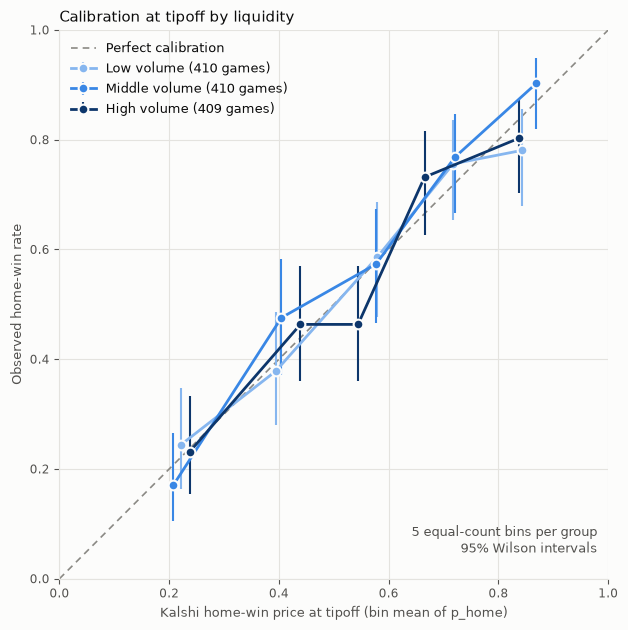

In [4]:
fig = show("liquidity")

**Primary test.** The joint test that the slope is the same in the three groups gives χ² = 2.34 on 2 degrees of freedom, p = 0.31. It is not rejected. The slopes are 0.94 (low), 1.17 (middle) and 1.00 (high), and none differs from 1 (p = 0.54, 0.16 and 1.00).

**Brier score.** 0.2002 in the low group, 0.1786 in the middle group and 0.2043 in the high group. The middle group is the most accurate, and the low and high groups are alike.

- High minus low: +0.0041 (bootstrap -0.019 to 0.029, p = 0.72).
- Middle minus low: -0.0216 (bootstrap -0.045 to 0.003, p = 0.087).
- High minus middle: +0.0257 (bootstrap 0.006 to 0.047, p = 0.012).

**What the numbers show.** There is no sign that calibration gets better or worse with volume. One of the three Brier comparisons has an interval that excludes 0, but it is a secondary result, and it does not line up with volume: the least traded and the most traded games score the same. A Brier difference can also come from a different mix of close and lopsided games.

## 4. Season half

,group,n,home_win_rate,brier,brier_baseline,brier_skill,intercept_a,a_p_value,slope_b,b_se_cluster,b_p_value,b_boot_lo,b_boot_hi
0,early,611,0.5581,0.2169,0.2466,0.1206,0.0853,0.2443,0.8162,0.1003,0.0669,0.6361,1.0333
1,late,618,0.5518,0.1720,0.2473,0.3044,-0.0625,0.3749,1.2612,0.1021,0.0105,1.0776,1.4711


,term,estimate,se_cluster,ci_lo,ci_hi,statistic,statistic_name,df,p_value,boot_lo,boot_hi
0,intercept_a,0.0853,0.0733,-0.0583,0.2289,1.1639,z,<NA>,0.2445,-0.0625,0.2418
1,slope_b,0.8162,0.1003,0.6195,1.0129,-1.8318,z,<NA>,0.0670,0.6361,1.0333
2,intercept_shift_late,-0.1478,0.1164,-0.3759,0.0802,-1.2704,z,<NA>,0.2039,-0.3863,0.1025
3,slope_shift_late,0.4451,0.1546,0.1421,0.7480,2.8797,z,<NA>,0.0040,0.1784,0.7253
4,all_slope_shifts,NaN,NaN,NaN,NaN,8.2925,chi2,1,0.0040,NaN,NaN


,split,group,minus_group,brier_group,brier_minus_group,brier_diff,boot_lo,boot_hi,p_bootstrap
0,season_half,late,early,0.172,0.2169,-0.0448,-0.0639,-0.025,0.001


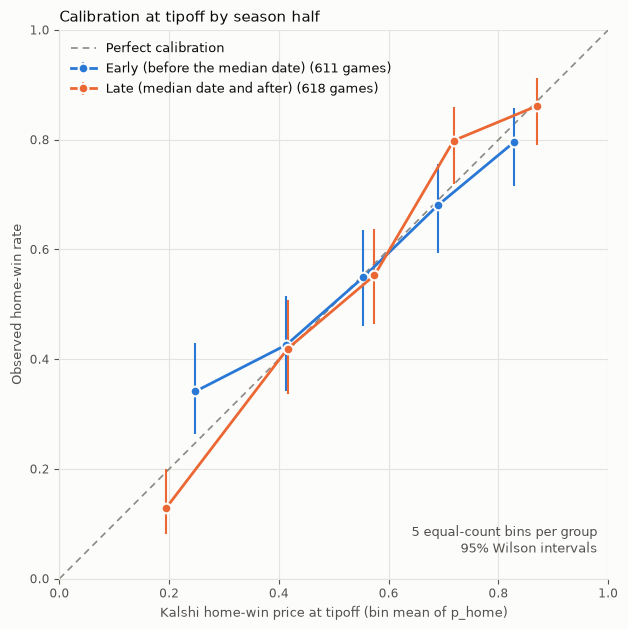

In [5]:
fig = show("season_half")

**Primary test.** The slope in the late half minus the slope in the early half is 0.445, with clustered SE 0.155 (z = 2.88, p = 0.0040). The clustered 95% interval is 0.142 to 0.748 and the bootstrap interval is 0.178 to 0.725. Both exclude 0. The bound 8 · p is 0.032, below 0.05, so this test stays significant after the Holm adjustment whatever the other primary tests give.

**The two slopes.**
- Early half: b = 0.816 (SE 0.100, p = 0.067 for b = 1). Below 1 means prices too extreme: favorites won a little less often than priced. On its own this is not distinguishable from 1.
- Late half: b = 1.261 (SE 0.102, p = 0.011). Above 1 means prices not extreme enough: favorites won more often than priced.

In the figure, the gap shows at the ends. In the late half, home teams priced near 19% won 13% of the time and home teams priced near 72% won 80%. In the early half, home teams priced near 25% won 34%.

**Brier score.** 0.2169 in the early half and 0.1720 in the late half. Late minus early is -0.0448 (bootstrap -0.064 to -0.025, p = 0.001). The skill score is 0.12 early and 0.30 late.

**What the numbers show.** The calibration slope was different in the two halves of the season, in opposite directions around 1. Pooled over the season, the two cancel: the Stage 8 slope was 1.035. The late half also has the lower Brier score.

**Limits.**
- The Brier difference is partly a matter of the games. Late-season prices are more spread out (bin means from 0.19 to 0.87, against 0.25 to 0.83 early), and lopsided games are easier to forecast.
- The cut at the median date was fixed in the plan and no other cut was tried, so the result says the halves differ. It does not say when or why the slope changed.
- This is one season. Notebook 09 gives a first look at early 2026-27.

## 5. Rest

,group,n,home_win_rate,brier,brier_baseline,brier_skill,intercept_a,a_p_value,slope_b,b_se_cluster,b_p_value,b_boot_lo,b_boot_hi
0,rested,858,0.5711,0.1911,0.2449,0.2200,0.0913,0.1163,1.0809,0.0834,0.3321,0.9226,1.2767
1,back_to_back,371,0.5175,0.2019,0.2497,0.1914,-0.1439,0.1639,0.9495,0.1114,0.6501,0.7476,1.1999


,term,estimate,se_cluster,ci_lo,ci_hi,statistic,statistic_name,df,p_value,boot_lo,boot_hi
0,intercept_a,0.0913,0.0582,-0.0227,0.2054,1.5697,z,<NA>,0.1165,-0.0440,0.2359
1,slope_b,1.0809,0.0835,0.9173,1.2445,0.9693,z,<NA>,0.3324,0.9226,1.2767
2,intercept_shift_back_to_back,-0.2352,0.1330,-0.4959,0.0254,-1.7690,z,<NA>,0.0769,-0.5093,0.0392
3,slope_shift_back_to_back,-0.1314,0.1485,-0.4225,0.1596,-0.8851,z,<NA>,0.3761,-0.4191,0.1518
4,all_slope_shifts,NaN,NaN,NaN,NaN,0.7834,chi2,1,0.3761,NaN,NaN


,split,group,minus_group,brier_group,brier_minus_group,brier_diff,boot_lo,boot_hi,p_bootstrap
0,rest,back_to_back,rested,0.2019,0.1911,0.0108,-0.0091,0.0321,0.2979


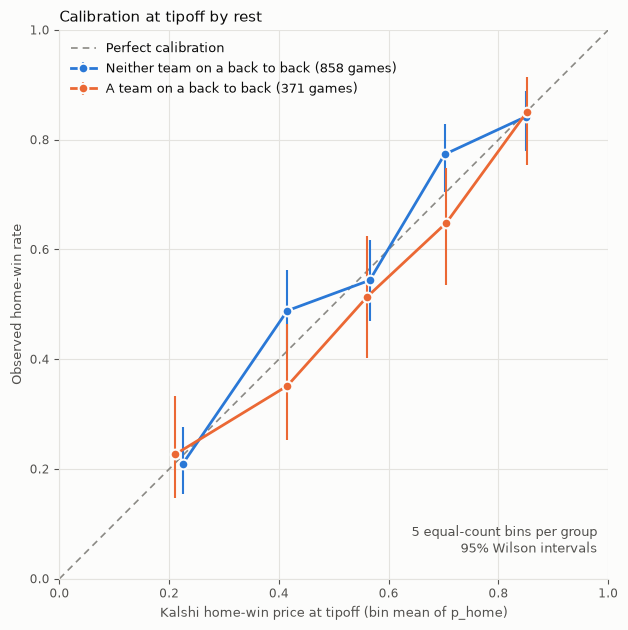

In [6]:
fig = show("rest")

**Primary test.** The slope in back to back games minus the slope in the other games is -0.131, with clustered SE 0.149 (p = 0.38). The clustered 95% interval is -0.42 to 0.16. It is not distinguishable from 0. The slopes are 1.08 (rested) and 0.95 (back to back), and neither differs from 1.

**Intercept.** The intercept is lower in back to back games by 0.235 (SE 0.133, p = 0.077). The sign means the home team won less often than priced in those games, but the difference is not distinguishable from 0, and it is a secondary test.

**Brier score.** 0.1911 in rested games and 0.2019 in back to back games. The difference is +0.0108 (bootstrap -0.009 to 0.032, p = 0.30).

**What the numbers show.** No difference in calibration or accuracy between back to back games and the rest that the data can tell from 0.

## 6. All tests of this notebook

Every test above in the common Stage 10 layout. `p_bound` is min(1, 8 · p) for the primary tests: the Holm adjusted p value across the 8 primary tests of Stage 10 can never be above it. The Holm values themselves need all 8 tests and are added by notebook 10.

In [7]:
tests = tables["tests"]
shown = tests[["test_id", "role", "n", "estimate", "ci_lo", "ci_hi", "statistic", "df",
               "p_raw"]].copy()
shown["p_bound"] = all_tests.bonferroni_bound(shown["p_raw"]).where(shown["role"] == "primary")
display(shown.round(4))

,test_id,role,n,estimate,ci_lo,ci_hi,statistic,df,p_raw,p_bound
0,subgroup_liquidity_slope,primary,1229,NaN,NaN,NaN,2.3407,2,0.3103,1.0000
1,subgroup_liquidity_slope_middle,secondary,1229,0.2262,-0.0736,0.5259,1.4790,<NA>,0.1391,NaN
2,subgroup_liquidity_slope_high,secondary,1229,0.0578,-0.2528,0.3684,0.3649,<NA>,0.7152,NaN
3,subgroup_liquidity_intercept_middle,secondary,1229,0.0961,-0.2116,0.4038,0.6123,<NA>,0.5404,NaN
4,subgroup_liquidity_intercept_high,secondary,1229,-0.0298,-0.2860,0.2265,-0.2276,<NA>,0.8200,NaN
5,subgroup_liquidity_low_a,secondary,410,0.0005,-0.1429,0.1439,0.0068,<NA>,0.9945,NaN
6,subgroup_liquidity_low_b,secondary,410,0.9420,0.7565,1.1276,-0.6122,<NA>,0.5404,NaN
7,subgroup_liquidity_middle_a,secondary,410,0.0966,-0.1237,0.3170,0.8596,<NA>,0.3900,NaN
8,subgroup_liquidity_middle_b,secondary,410,1.1682,0.9310,1.4055,1.3898,<NA>,0.1646,NaN
9,subgroup_liquidity_high_a,secondary,409,-0.0293,-0.2173,0.1588,-0.3050,<NA>,0.7604,NaN


**Primary tests.**
- Liquidity: p = 0.310. The bound 8 · p is 1. Not significant.
- Season half: p = 0.0040. The bound 8 · p is 0.032. Significant after the Holm adjustment, whatever the other primary tests give.
- Rest: p = 0.376. The bound 8 · p is 1. Not significant.

**Secondary tests.** 25 tests, with no adjustment. Three have a p value below 0.05: the late-half slope against 1 (0.011), the Brier difference between the season halves (0.001) and the Brier difference between the high and middle volume groups (0.012). The first two are the season-half finding seen from another side. With 25 unadjusted tests, one or two below 0.05 are expected by chance alone.

**In short.** Of the three splits, only the season half shows a difference in calibration: prices were, if anything, too extreme early and not extreme enough late. Volume and rest show none.

---

# Exploratory (not in the Stage 10 plan): calibration slope by month

**This section was added after the Stage 10 results above were seen.** It follows `ANALYSIS_PLAN.md`, "Exploratory, added after Stage 10 results", check X2, which was committed before this was run. Its results carry less weight than the planned tests above. They are in `results/stage10_all_tests.csv` with the role `exploratory` and get no Holm adjustment.

**Reason.** Section 4 found a lower slope in the early half of the season than in the late half. A cut at one date cannot show whether the slope changed at one point or drifted over the season.

**What is computed.** The games are grouped by the calendar month of the game date. A first or last month with fewer than 100 games is combined with the month next to it. Within each group, the recalibration fit logit P(home win) = a + b · logit(p), with standard errors clustered by home team, and the Wald test of b = 1. No test of a difference between months is run.

,month_label,n,first_game_date,last_game_date,home_win_rate,n_clusters,intercept_a,a_p_value,slope_b,b_se_cluster,b_ci_lo,b_ci_hi,b_p_value
0,Oct to Nov,299,2025-10-21,2025-11-30,0.5619,30,0.0394,0.7709,1.1260,0.1603,0.8119,1.4402,0.4317
1,Dec,197,2025-12-01,2025-12-31,0.5330,30,0.0402,0.7866,0.5111,0.1389,0.2389,0.7833,0.0004
2,Jan,232,2026-01-01,2026-01-31,0.5603,30,0.0889,0.4296,0.8336,0.1598,0.5205,1.1468,0.2977
3,Feb,166,2026-02-01,2026-02-28,0.4699,30,-0.4894,0.0173,1.3893,0.2444,0.9103,1.8683,0.1112
4,Mar to Apr,335,2026-03-01,2026-04-12,0.6000,30,0.2062,0.1206,1.2982,0.1323,1.0390,1.5574,0.0242


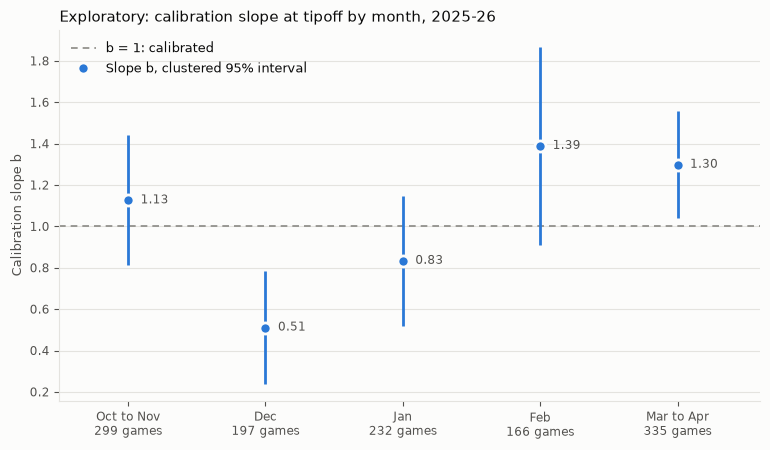

In [8]:
from subgroups import monthly_figure, monthly_slopes, monthly_tests

by_month = monthly_slopes(d)
write_csv(by_month, RESULTS_DIR / "exploratory_slope_by_month.csv")
write_csv(monthly_tests(by_month), all_tests.part_path("exploratory_subgroups"))
display(by_month[["month_label", "n", "first_game_date", "last_game_date", "home_win_rate",
                  "n_clusters", "intercept_a", "a_p_value", "slope_b", "b_se_cluster",
                  "b_ci_lo", "b_ci_hi", "b_p_value"]].round(4))
fig = monthly_figure(by_month, RESULTS_DIR / "exploratory_slope_by_month.png")

**Groups.** October has 80 games and April 96, both under 100, so October is combined with November and April with March. That gives five groups: October to November (299 games), December (197), January (232), February (166) and March to April (335).

**The slopes.**
- October to November: b = 1.13 (clustered interval 0.81 to 1.44, p = 0.43 for b = 1).
- December: b = 0.51 (0.24 to 0.78, p = 0.0004).
- January: b = 0.83 (0.52 to 1.15, p = 0.30).
- February: b = 1.39 (0.91 to 1.87, p = 0.11).
- March to April: b = 1.30 (1.04 to 1.56, p = 0.024).

**What the numbers show.** The slope did not drift steadily upward over the season. The low slope of the early half comes mostly from December, when favorites won far less often than priced, and the season did not start low: October to November is above 1. From February on the estimates are above 1, and March to April is the one group besides December whose interval excludes 1.

**Intercept.** February has a negative intercept (a = -0.49, p = 0.017): home teams won less often than priced that month (the home-win rate is 47%). The other four intercepts are not distinguishable from 0.

**Limits.**
- This check was chosen after seeing the season-half result, and these are five unadjusted tests on groups of 166 to 335 games. December's p value of 0.0004 would survive a correction for five tests. March to April's 0.024 would not.
- No test compares the months with each other. The intervals are wide. December's interval lies below those of every other group except January, and the other four overlap one another.
- January holds both halves of the planned split, whose cut is January 16.
- It is one season. The data cannot say whether December 2025 was unusual or whether a low slope in December would come back.